# Synthetic biomarker benchmark — AutoMorph and its two rewrites

This notebook is one of three, one per **lineage** of biomarker software, beside a
[summary notebook](biomarker-synthetic.ipynb) that compares the three over the catalogue's own
names. It reads the evidence of one run of the benchmark and argues about what it shows for this
group alone: `automorph`, `automorphalyzer`, `automorphclass`.

**AutoMorph** is the ancestor: its measuring stage is retipy's code, run by driver scripts. **AutoMorphalyzer** and **AutoMorphClass** are two independent rewrites of that stage, each by different authors. So within this group, a difference between AutoMorph and a rewrite is a change somebody made on purpose, and agreement between the three is evidence about the code they share rather than three separate confirmations.

## What this benchmark is

**It measures over synthetically generated segmentations**: drawn arteries, veins, an optic disc
and an optic cup, not photographs. No eye was photographed and no annotator was consulted. The
shapes, and what each one settles, are in the
[shapes notebook](biomarker-synthetic-shapes.ipynb).

**There are two kinds of benchmarking here, and they are different questions.**

1. **Sensitivity to rotation.** The same shape is drawn at seven angles, every 15° of a quarter
   turn. The geometry is identical at each, so anything that moves is the implementation or the
   pixel grid. This needs no ground truth: it is a self-consistency check, and an implementation
   can fail it while agreeing with the ground truth on average.
2. **Agreement with ground truth.** The ground truth is a theoretical value derived from the
   geometry before anything was drawn, stored beside the images, not an annotation and not
   another program's output. There are two:
   - **by canonical name**, for every column an adapter maps onto the catalogue, using the
     definition the catalogue records for that biomarker (the paper that introduced it, where
     there is one);
   - **by the program's own description**, for the columns the catalogue cannot name: what the
     column's name, docstring or cited paper says it computes, worked out on the same geometry
     (`src/benchmarks/shapes/claims.py`). This is how a column like PVBM's tortuosity index is
     checked at all.

**How to read the tables.** Rows are columns **under the names this lineage's own project gives
them** — AutoMorph's — with each sibling's column on the row of the AutoMorph column it is a rewrite of
(`se.native`); a column with no AutoMorph counterpart keeps its own name, with its implementation's
after it. The last column, **canonical**, says which catalogued biomarker each row answers to, and
where siblings pool it differently, each one's. Columns are this group's implementations, in
lineage order. Where a quantity was measured on several shapes or
at several angles, the cell is the **worst** of them, because a mean would hide the case that
matters. Percentages are of the required value. A difference smaller than 1% of a biomarker's own
size is treated as no difference: that is the pixel grid's floor, argued in the summary notebook.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"nothing above {Path.cwd()} looks like the fundus-atlas repository")


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_synthetic as benchmark  # noqa: E402
from benchmarks import synthetic_evidence as se  # noqa: E402
from benchmarks.shapes import claims  # noqa: E402

#: This notebook's group, from the benchmark's own declaration, in lineage order.
GROUP = "automorph"
IMPLEMENTATIONS = list(benchmark.GROUPS[GROUP])

#: The two reporting thresholds. Neither is a standard anybody agreed: they decide which rows a
#: table shows, not whether anything passes. Nothing passes or fails here.
ROTATION_TOLERANCE = se.ROTATION_TOLERANCE
GROUND_TRUTH_TOLERANCE = se.GROUND_TRUTH_TOLERANCE

EVIDENCE = se.read(IMPLEMENTATIONS, ROOT)
AGAINST = se.agreement(EVIDENCE)
CLAIMED = se.claimed_agreement(EVIDENCE)

#: Every table is indexed by each column's name in this lineage's own project (`se.native`), and
#: carries the canonical name it answers to as its last column.
ROW = "native"
COMMENTS = se.comments(EVIDENCE)


def commented(table):
    # A table indexed by native name, with the canonical name each row answers to appended.
    shown = table.copy()
    rows = shown.index.get_level_values(ROW) if ROW in (shown.index.names or []) else shown.index
    shown["canonical"] = COMMENTS.reindex(rows).fillna("—").values
    return shown
pd.set_option("display.width", 200, "display.max_rows", 300, "display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif"})


def heading(text: str) -> None:
    display(Markdown(text))


print(
    f"{len(EVIDENCE.said):,} numbers from {len(IMPLEMENTATIONS)} implementation(s) × "
    f"{len(EVIDENCE.shapes)} shapes × {EVIDENCE.said['rotation'].nunique()} angles; "
    f"{len(AGAINST):,} judged by canonical name and {len(CLAIMED):,} by their own description"
)

17,836 numbers from 3 implementation(s) × 13 shapes × 7 angles; 10,036 judged by canonical name and 3,185 by their own description


## 1. Coverage — how much there is, and how much of it can be judged

How many columns each implementation returns, how many of them carry a canonical name, and what
happens to the rest. A column with no canonical name is still checked here when the shapes can
settle what its own description says it computes; the last two rows say how many can and cannot.

In [2]:
se.coverage(EVIDENCE)

,automorph,automorphalyzer,automorphclass
columns it returns,72.0,66.0,60.0
…that returned a value,72.0,52.0,60.0
matching a canonical name,57.0,40.0,33.0
"…of those, returning a value",57.0,40.0,33.0
"unnamed, but returning a value",15.0,12.0,27.0
…held to their own description,15.0,11.0,12.0
…whose description the shapes cannot settle,0.0,1.0,15.0
seconds per image,8.5,7.3,0.5


### 1.1 The columns with no canonical name, and what each claims

Every column the catalogue cannot name, with what its authors say it computes and where they say
it. Those marked *cannot be settled* are claims the shapes have no value for (most need a fovea,
which no shape places); they are measured and stored, and checked only for rotation in §3.2.

In [3]:
rows = []
for slug in IMPLEMENTATIONS:
    mine = claims.claimed(slug)
    for own, name in EVIDENCE.names[slug].items():
        if name:
            continue
        claim = mine.get(own)
        rows.append(
            {
                "implementation": slug,
                "its own name": own,
                "claims to compute": claim.claims if claim else "—",
                "held to": (
                    claim.canonical or "a value derived from the geometry"
                    if claim and not claim.unsettled
                    else ("cannot be settled: " + claim.unsettled if claim else "not claimed")
                ),
            }
        )
UNNAMED = pd.DataFrame(rows)
UNNAMED if len(UNNAMED) else print("every column it returns has a canonical name")

,implementation,its own name,claims to compute,held to
0,automorph,squared_curvature_tortuosity_binary,"Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are",tortuosity/hart-tau3/vessels/mean
1,automorph,squared_curvature_tortuosity_artery,"Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are",tortuosity/hart-tau3/artery/mean
2,automorph,squared_curvature_tortuosity_vein,"Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are",tortuosity/hart-tau3/vein/mean
3,automorph,vessel_density_binary_zone_b,"the zone's vessel pixels over every pixel of the frame, the zone being 2 to 3 disc radii",a value derived from the geometry
4,automorph,squared_curvature_tortuosity_binary_zone_b,"Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone",tortuosity/hart-tau3/vessels/B/mean
5,automorph,vessel_density_artery_zone_b,"the zone's vessel pixels over every pixel of the frame, the zone being 2 to 3 disc radii",a value derived from the geometry
6,automorph,squared_curvature_tortuosity_artery_zone_b,"Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone",tortuosity/hart-tau3/artery/B/mean
7,automorph,vessel_density_vein_zone_b,"the zone's vessel pixels over every pixel of the frame, the zone being 2 to 3 disc radii",a value derived from the geometry
8,automorph,squared_curvature_tortuosity_vein_zone_b,"Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone",tortuosity/hart-tau3/vein/B/mean
9,automorph,vessel_density_binary_zone_c,"the zone's vessel pixels over every pixel of the frame, the zone being 2 to 5 disc radii",a value derived from the geometry


## 2. Hard failures — what raised, and on what

Every exception an adapter caught, and every rendering nothing came back for: which quantity,
which shape, which angle. A failure is not a bad measurement: an implementation that raises has
said it could not answer, and one that returns a confident wrong number has not.

In [4]:
TROUBLES = se.troubles(EVIDENCE)
print(f"{len(TROUBLES)} exceptions over {EVIDENCE.said['key'].nunique()} renderings")
TROUBLES

63 exceptions over 91 renderings


,implementation,shape,rotation,what it could not answer,what it raised
0,automorph,disjoint,0.0,evaluate_binary_zone_b,ValueError('No windows were created for the given retinal image')
1,automorph,disjoint,0.0,evaluate_artery_zone_b,ValueError('No windows were created for the given retinal image')
2,automorph,disjoint,0.0,evaluate_vein_zone_b,ValueError('No windows were created for the given retinal image')
3,automorph,disjoint,0.0,evaluate_binary_zone_c,ValueError('No windows were created for the given retinal image')
4,automorph,disjoint,0.0,evaluate_artery_zone_c,ValueError('No windows were created for the given retinal image')
5,automorph,disjoint,0.0,evaluate_vein_zone_c,ValueError('No windows were created for the given retinal image')
6,automorph,disjoint,15.0,evaluate_binary_zone_b,ValueError('No windows were created for the given retinal image')
7,automorph,disjoint,15.0,evaluate_artery_zone_b,ValueError('No windows were created for the given retinal image')
8,automorph,disjoint,15.0,evaluate_vein_zone_b,ValueError('No windows were created for the given retinal image')
9,automorph,disjoint,15.0,evaluate_binary_zone_c,ValueError('No windows were created for the given retinal image')


## 3. Sensitivity to rotation

The geometry is identical at every angle, so any spread is the implementation or the grid. Each
cell is the **worst spread a quantity showed on any one shape**, max minus min over the seven
angles as a percentage of its mean there. The vertical and horizontal cup-to-disc ratios are left
out: they are read along the image's axes, so turning the photograph is meant to move them.

### 3.1 The columns with a canonical name

In [5]:
ROTATION = se.rotation(EVIDENCE, named=True, by=ROW).unstack("implementation")
ROTATION = EVIDENCE.in_order(ROTATION)
unsteady = se.over(ROTATION, ROTATION_TOLERANCE)
print(
    f"{len(unsteady)} of {len(ROTATION)} named columns move by more than "
    f"{ROTATION_TOLERANCE:.0%} somewhere; worst shape:"
)
commented(se.legible(unsteady))

41 of 53 named columns move by more than 10% somewhere; worst shape:


implementation,automorph,automorphalyzer,automorphclass,canonical
native,,,,
AVR_Hubbard_zone_c,10.4%,—,—,calibre/AVR-hubbard/both/C
AVR_Knudtson_zone_c,10.1%,24.2%,—,calibre/AVR-knudtson/both/C
CRAE_Hubbard_zone_c,10.1%,—,—,calibre/CRE-hubbard/artery/C
CRVE_Knudtson_zone_c,4.0%,19.5%,—,calibre/CRE-knudtson/vein/C
average_width_artery,63.0%,63.6%,63.0%,calibre/width/artery/length-weighted
average_width_artery_zone_b,28.1%,—,31.0%,calibre/width/artery/B/length-weighted
average_width_artery_zone_c,76.8%,—,—,calibre/width/artery/C/length-weighted
average_width_binary,79.1%,51.9%,79.1%,calibre/width/vessels/length-weighted
average_width_binary_zone_b,29.9%,—,40.4%,calibre/width/vessels/B/length-weighted


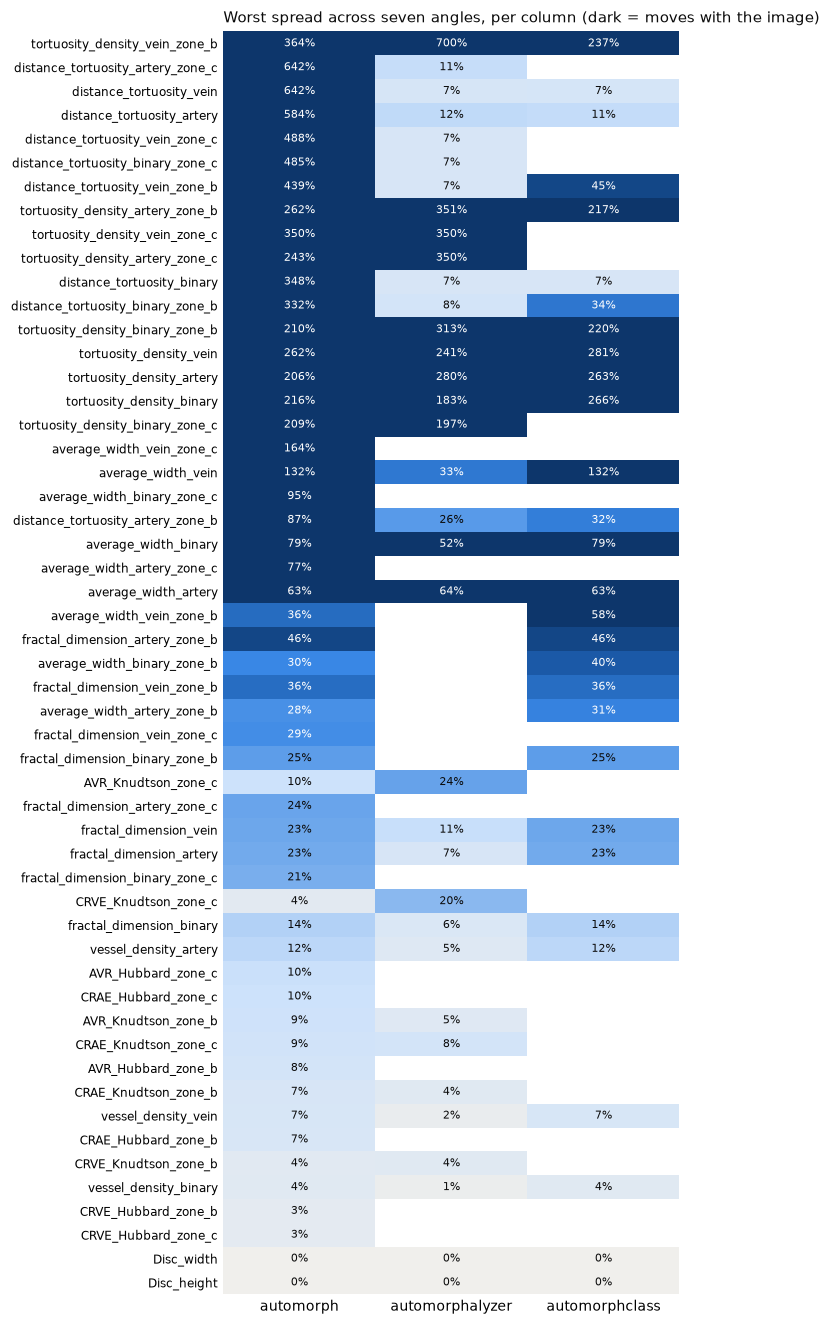

In [6]:
if len(ROTATION):
    shown = ROTATION.loc[ROTATION.max(axis=1).sort_values(ascending=False).index]
    se.heat(
        shown,
        "Worst spread across seven angles, per column (dark = moves with the image)",
        cap=0.5,
    )
    plt.show()

### 3.2 The columns with no canonical name

The same check on every unnamed column. Nothing can compare these with a definition, but they are
as capable of turning with the image as anything else, and nothing else would notice.

In [7]:
OWN_ROTATION = se.rotation(EVIDENCE, named=False, by=ROW)
if OWN_ROTATION.empty:
    print("nothing unnamed to check")
else:
    table = OWN_ROTATION.rename("worst spread").to_frame()
    moving = table[table.iloc[:, 0] > ROTATION_TOLERANCE]
    print(
        f"{len(moving)} of {len(table)} unnamed columns move by more than {ROTATION_TOLERANCE:.0%}"
    )
    display(se.legible(moving.sort_values("worst spread", ascending=False)))

43 of 51 unnamed columns move by more than 10%


worst spread
implementation  native                                                                   
automorph       squared_curvature_tortuosity_artery_zone_b                         700.0%
                squared_curvature_tortuosity_vein                                  699.8%
                squared_curvature_tortuosity_artery_zone_c                         699.0%
                squared_curvature_tortuosity_vein_zone_b                           627.0%
                squared_curvature_tortuosity_binary_zone_b                         600.0%
                squared_curvature_tortuosity_artery                                556.3%
                squared_curvature_tortuosity_vein_zone_c                           488.3%
                squared_curvature_tortuosity_binary                                468.6%
                squared_curvature_tortuosity_binary_zone_c                         417.8%
automorphclass  squared_curvature_tortuosity_vein                                  294.1%
                tortuosity_density_vein_zone_c (automorphclass)                    265.8%
                tortuosity_density_vessels_zone_c (automorphclass)                 264.5%
                tortuosity_density_artery_zone_c (automorphclass)                  264.4%
                squared_curvature_tortuosity_vein_zone_c (automorphclass)          255.6%
                squared_curvature_tortuosity_artery                                252.8%
                squared_curvature_tortuosity_binary                                249.9%
                squared_curvature_tortuosity_vessels_zone_c (automorphclass)       242.2%
                squared_curvature_tortuosity_vein_zone_b                           238.8%
                squared_curvature_tortuosity_artery_zone_c (automorphclass)        236.4%
                squared_curvature_tortuosity_artery_zone_b                         175.6%
                squared_curvature_tortuosity_binary_zone_b                         168.5%
                average_width_vein_zone_c (automorphclass)                         149.6%
                average_width_vessels_zone_c (automorphclass)                       99.7%
                average_width_artery_zone_c (automorphclass)                        90.2%
                fractal_dimension_artery_zone_c (automorphclass)                    37.5%
                fractal_dimension_vein_zone_c (automorphclass)                      30.2%
automorphalyzer average_local_calibre@whole_vein (automorphalyzer)                  27.3%
automorphclass  fractal_dimension_vessels_zone_c (automorphclass)                   23.2%
                distance_tortuosity_artery_zone_c (automorphclass)                  22.0%
                vessel_density_artery_zone_c (automorphclass)                       16.3%
                distance_tortuosity_vessels_zone_c (automorphclass)                 14.9%
                distance_tortuosity_vein_zone_c (automorphclass)                    13.1%
automorphalyzer average_local_calibre@whole_binary (automorphalyzer)                13.0%
automorphclass  vessel_density_artery_zone_b                                        12.8%
automorph       vessel_density_artery_zone_b                                        12.8%
                vessel_density_artery_zone_c                                        12.4%
automorphclass  vessel_density_vessels_zone_c (automorphclass)                      11.7%
automorphalyzer average_local_calibre@whole_artery (automorphalyzer)                10.8%
                average_local_calibre@C_artery (automorphalyzer)                    10.7%
                average_local_calibre@B_binary (automorphalyzer)                    10.3%
automorph       vessel_density_vein_zone_b                                          10.1%
automorphclass  vessel_density_vein_zone_b                                          10.1%
automorphalyzer average_local_calibre@B_artery (automorphalyzer)                    10.1%

### 3.3 Shape by shape, for what moves by more than half

For each implementation, every column — named or not, under AutoMorph's own names — whose spread
across the seven angles is **more than 50%** on at least one shape, against every shape. A row dark
on one shape and light on the rest is a column that one geometry upsets; a row dark everywhere moves
with the picture whatever is drawn. Blank is a shape the column gave no number on.

#### 3.3.1 automorph — 33 of 68 columns move by more than 50%

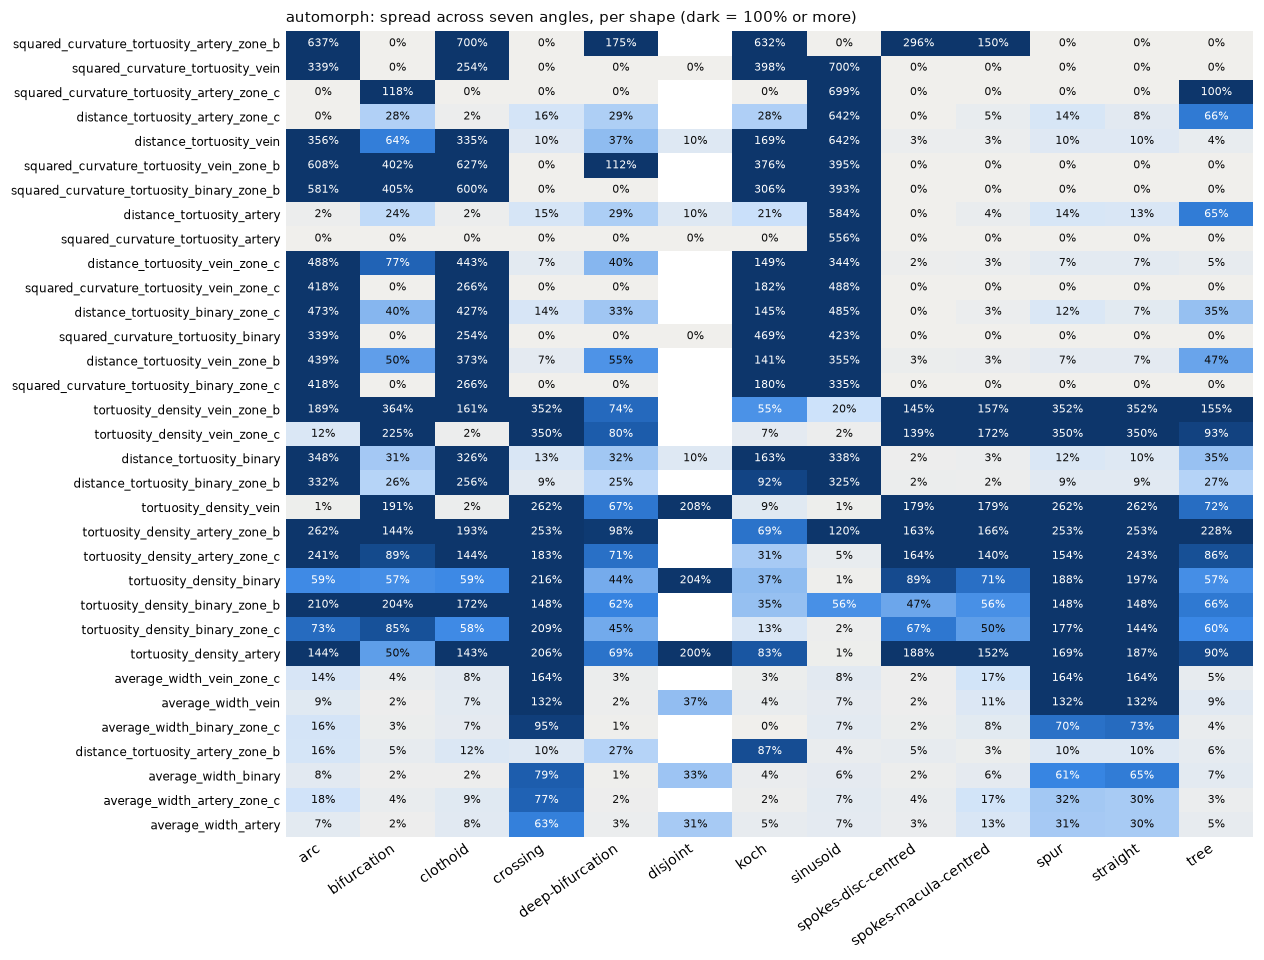

#### 3.3.2 automorphalyzer — 11 of 44 columns move by more than 50%

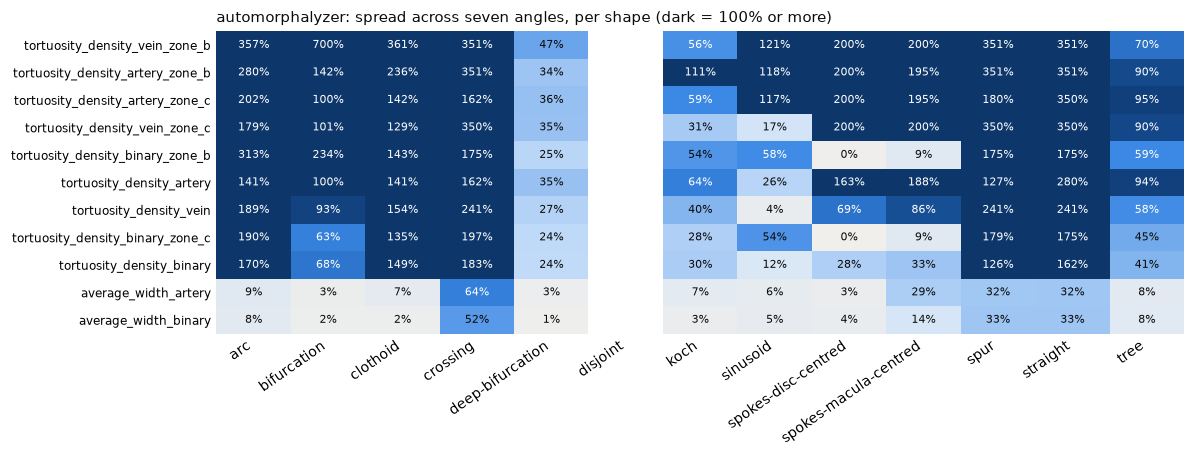

#### 3.3.3 automorphclass — 25 of 56 columns move by more than 50%

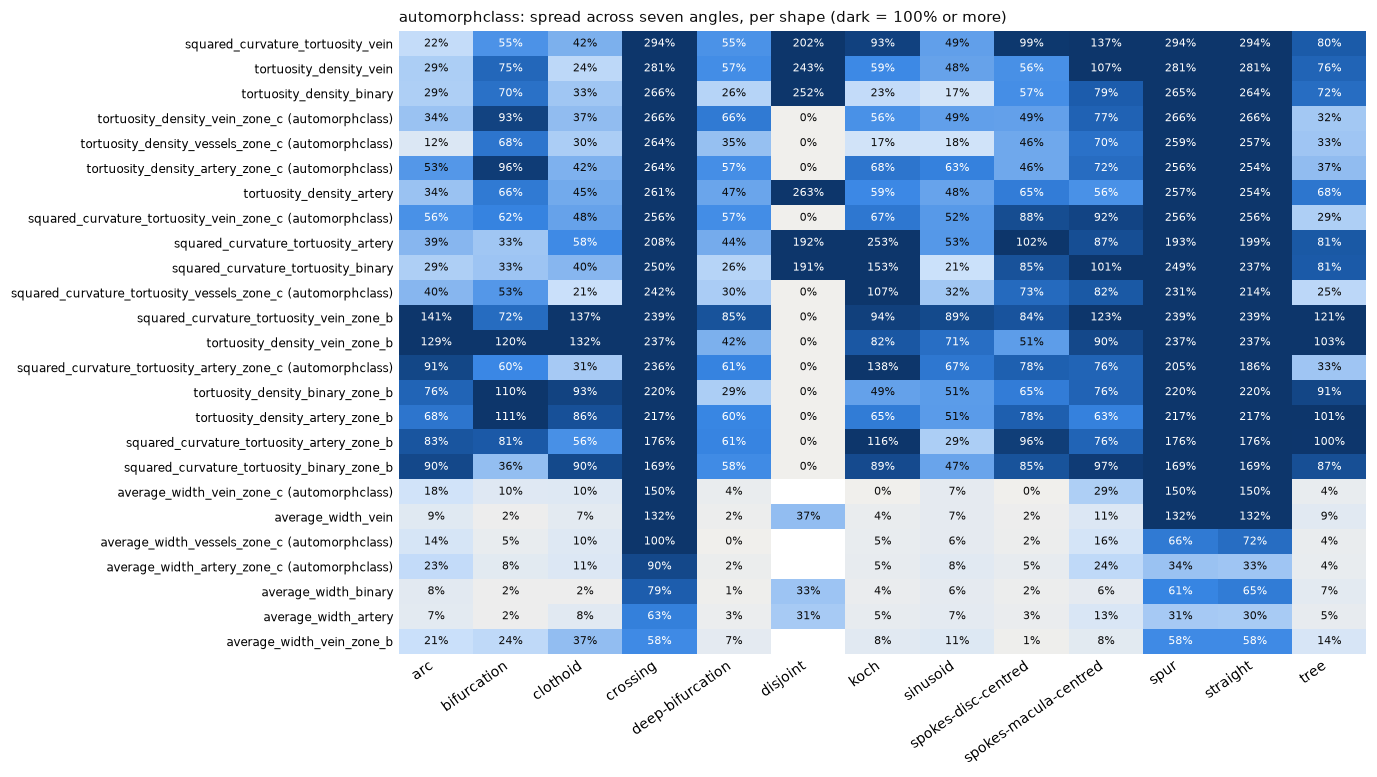

In [8]:
BY_SHAPE = se.rotation_by_shape(EVIDENCE, by=ROW)
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    mine = BY_SHAPE[BY_SHAPE["implementation"] == slug].pivot_table(
        index=ROW, columns="shape", values="spread", aggfunc="max"
    )
    mine = mine.reindex(columns=EVIDENCE.shapes)
    wide = mine[mine.max(axis=1) > 0.5]
    heading(f"#### 3.3.{number} {slug} — {len(wide)} of {len(mine)} columns move by more than 50%")
    if wide.empty:
        print("no column moves by more than 50% on any shape")
        continue
    wide = wide.loc[wide.max(axis=1).sort_values(ascending=False).index]
    se.heat(wide, f"{slug}: spread across seven angles, per shape (dark = 100% or more)")
    plt.show()

**What the maps show.** Three different faults, and the lineage shares two of them.

- **Width grows when a vessel runs diagonally.** On the straight shape, AutoMorph's
  `average_width_artery` is 72 px at 0°, 98 px at 45° and 72 px again at 90°. AutoMorphalyzer
  goes from 77 to 106 and back. The ratio is about 1.36, close to √2 (1.41), the factor you get
  when a width is measured along the image's rows or columns instead of straight across the
  vessel. The fault shows wherever the vessels are straight (straight, spur and crossing, 30–164%)
  and nearly disappears on curved shapes (mostly under 20%). A curve runs in every
  direction, so the over-reading averages out over the vessel rather than vanishing. AutoMorphClass
  measures width with the same code and shows the same pattern.
- **Tortuosity density calls a diagonal straight line tortuous.** On the straight shape,
  AutoMorph's `tortuosity_density_artery` is 0 at 0° and 90° and about 0.15 at most angles in
  between. A diagonal line drawn in pixels becomes a staircase, and the measurement reads the steps
  as bends. Every tortuosity-density column of all three members is dark on most shapes.
  AutoMorphClass's values are about fifty times smaller (0.003 where AutoMorph says 0.15) but swing
  the same way.
- **AutoMorph's curvature and distance tortuosity break on curved shapes, at some angles only.**
  The two columns are nearly steady on straight vessels (16% at most on straight, spur and
  crossing) and dark on
  the arc, clothoid, Koch curve and sinusoid. On the arc, the vein's `squared_curvature_tortuosity`
  is 1.17 at 0°, 1,585 at 45° and 0.36 at 90°. Its `distance_tortuosity` (arc length over chord) is
  1.15 at 0° and 167 at 45°. No arc is 167 times longer than its chord, so at those angles the
  program is not measuring the drawn vessel. AutoMorphalyzer has no squared-curvature column, and its
  distance tortuosity moves by 26% at most.
  AutoMorphClass shows a different pattern: its curvature tortuosity swings by 170–290% on
  straight, spur and crossing, where AutoMorph's hardly moves.

Whatever the shape, a reading from these columns depends on how the eye sat in the frame as much as
on the eye.

## 4. Agreement with ground truth, by canonical name

Every named measurement against the value the catalogue's definition requires of that shape.

### 4.1 The worst disagreement, over every shape and angle

In [9]:
EVERYWHERE = EVIDENCE.in_order(
    AGAINST.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
)
faults = se.over(EVERYWHERE, GROUND_TRUTH_TOLERANCE)
print(
    f"{len(AGAINST):,} measurements over {AGAINST[ROW].nunique()} named columns; "
    f"{len(faults)} are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere. Worst:"
)
commented(se.legible(faults.loc[faults.max(axis=1).sort_values(ascending=False).index]))

10,036 measurements over 57 named columns; 44 are out by more than 25% somewhere. Worst:


implementation,automorph,automorphalyzer,automorphclass,canonical
native,,,,
tortuosity_density_artery_zone_b,"329,877×","335,084×","6,051×",automorph: tortuosity/grisan-density/artery/B/mean; automorphalyzer: tortuosity/grisan...
tortuosity_density_vein_zone_b,"330,243×","334,735×","6,338×",automorph: tortuosity/grisan-density/vein/B/mean; automorphalyzer: tortuosity/grisan-d...
tortuosity_density_binary_zone_b,"322,502×","331,336×","6,196×",automorph: tortuosity/grisan-density/vessels/B/mean; automorphalyzer: tortuosity/grisa...
tortuosity_density_artery_zone_c,"201,751×","203,093×",—,tortuosity/grisan-density/artery/C/mean
tortuosity_density_vein_zone_c,"202,616×","203,091×",—,tortuosity/grisan-density/vein/C/mean
tortuosity_density_binary_zone_c,"201,021×","202,609×",—,tortuosity/grisan-density/vessels/C/mean
tortuosity_density_artery,"170,613×","171,365×","3,266×",automorph: tortuosity/grisan-density/artery/mean; automorphalyzer: tortuosity/grisan-d...
tortuosity_density_vein,"171,006×","171,364×","3,377×",automorph: tortuosity/grisan-density/vein/mean; automorphalyzer: tortuosity/grisan-den...
tortuosity_density_binary,"169,943×","170,618×","3,320×",automorph: tortuosity/grisan-density/vessels/mean; automorphalyzer: tortuosity/grisan-...


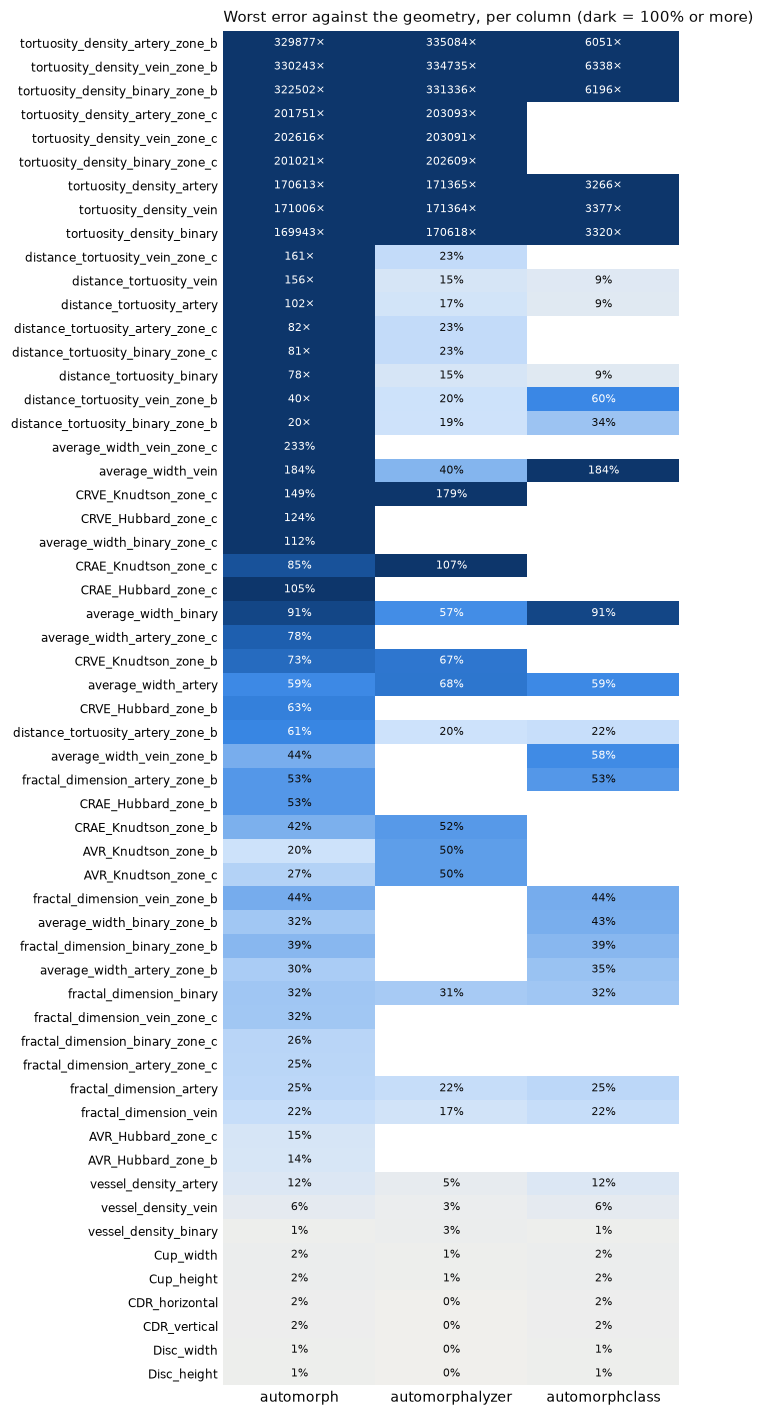

In [10]:
shown = EVERYWHERE.loc[EVERYWHERE.max(axis=1).sort_values(ascending=False).index]
se.heat(shown, "Worst error against the geometry, per column (dark = 100% or more)")
plt.show()

### 4.2 Where the errors fall

Every measurement of a biomarker that is out of tolerance somewhere, as one dot per shape and
angle, signed: right of the line the program said more than the geometry requires, left of it less.
The shaded band is the 25% tolerance. A tight cluster away from nought is a formula; a scatter is
the grid or the shape.

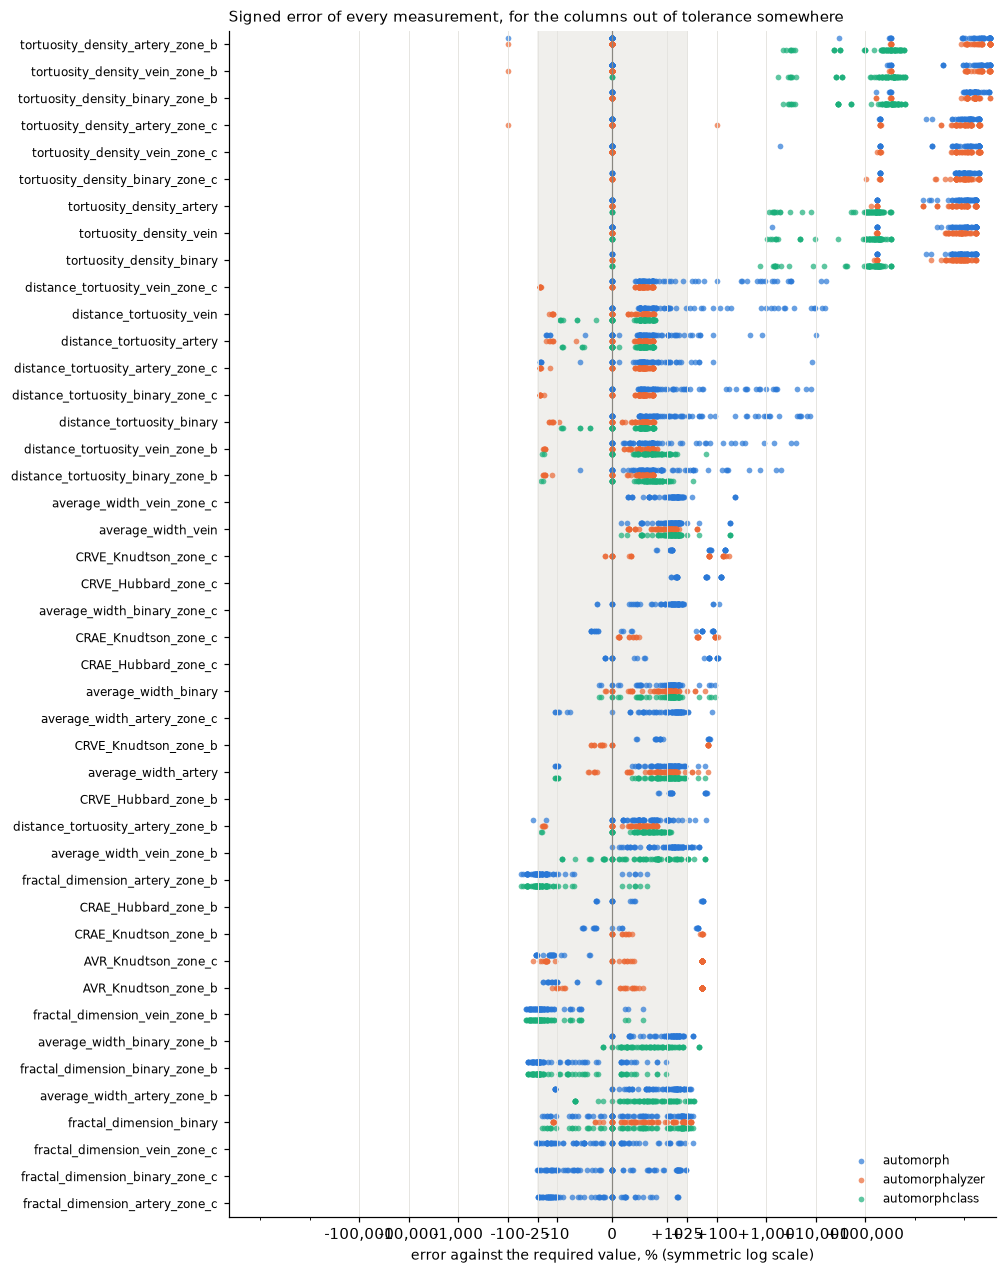

In [11]:
order = list(faults.max(axis=1).sort_values(ascending=False).index)
if order:
    se.strips(
        AGAINST[AGAINST[ROW].isin(order)],
        order,
        IMPLEMENTATIONS,
        "Signed error of every measurement, for the columns out of tolerance somewhere",
        index=ROW,
    )
    plt.show()
else:
    print("nothing is out of tolerance")

### 4.3 The same, one shape at a time

The worst over each shape's seven angles, for the biomarkers out of tolerance on that shape. A
biomarker wrong on one shape and right on the rest is a different finding from one wrong on all of
them, and §4.1 cannot tell them apart.

Each implementation gets four columns, all taken from **the one angle where its error was worst**:
the value the geometry requires there (*truth*), the number the program returned (*value*), how far
apart they are (*error*), and the angle (*rotation*). The truth is read at that angle rather than
once per shape because a few quantities, such as the vertical cup-to-disc ratio, are meant to
change as the picture turns. Truth and value are in the same unit, the one the ground truth
is stored in.

In [12]:
for number, shape in enumerate(EVIDENCE.shapes, start=1):
    here = AGAINST[AGAINST["shape"] == shape]
    worst = se.worst_readings(here, by=ROW, implementations=IMPLEMENTATIONS)
    errors = worst.xs("error", axis=1, level=1) if len(worst) else worst
    table = worst[(errors > GROUND_TRUTH_TOLERANCE).any(axis=1)] if len(worst) else worst
    if len(table):
        table = table.loc[errors.loc[table.index].max(axis=1).sort_values(ascending=False).index]
    heading(f"#### 4.3.{number} {shape} — {len(table)} out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    if table.empty:
        print("every comparable biomarker lands within tolerance on this shape")
    else:
        display(commented(se.readings(table)))

#### 4.3.1 arc — 21 out by more than 25%

automorph                            automorphalyzer                            automorphclass                             \
                                      truth   value     error rotation           truth   value     error rotation          truth     value   error rotation   
native                                                                                                                                                        
tortuosity_density_artery_zone_b          0  0.1543  329,877×      90°               0  0.1564  334,440×      90°              0  0.002395  5,122×      75°   
tortuosity_density_vein_zone_b            0  0.1536  328,536×      45°               0  0.1508  322,563×      90°              0  0.002652  5,671×      30°   
tortuosity_density_binary_zone_b          0  0.1474  315,193×      90°               0  0.1536  328,501×      90°              0  0.002468  5,277×      30°   
tortuosity_density_artery_zone_c          0   0.156  201,178×      90°               0  0.1572  202,705×      90°              —         —       —        —   
tortuosity_density_vein_zone_c            0  0.1571  202,616×      30°               0  0.1571  202,514×      90°              —         —       —        —   
tortuosity_density_binary_zone_c          0  0.1559  201,021×      90°               0  0.1571  202,609×      90°              —         —       —        —   
tortuosity_density_artery                 0  0.1564  169,946×      90°               0  0.1573  170,997×      90°              0  0.001826  1,984×      75°   
tortuosity_density_vein                   0  0.1573  170,952×      45°               0  0.1568  170,452×      75°              0  0.001806  1,963×      30°   
tortuosity_density_binary                 0  0.1561  169,638×      90°               0   0.157  170,618×      75°              0  0.001803  1,959×      75°   
distance_tortuosity_vein_zone_c       1.036   167.8      161×      30°           1.036   1.097      5.9%      75°              —         —       —        —   
distance_tortuosity_vein              1.065   166.8      156×      45°           1.065   1.127      5.8%      75°          1.065     1.137    6.7%       0°   
distance_tortuosity_binary_zone_c     1.029   84.42       81×      30°           1.029   1.088      5.7%      15°              —         —       —        —   
distance_tortuosity_binary            1.065   83.96       78×      45°           1.065   1.127      5.8%      75°          1.065     1.133    6.3%       0°   
distance_tortuosity_vein_zone_b       1.004   15.64       15×      45°           1.004   1.077      7.2%      15°          1.004     1.105   10.0%      30°   
distance_tortuosity_binary_zone_b     1.003   8.362    733.5%      45°           1.003   1.064      6.0%      30°          1.003     1.094    9.1%      30°   
AVR_Knudtson_zone_c                       —       —         —        —          0.6667       1     50.0%       0°              —         —       —        —   
AVR_Knudtson_zone_b                       —       —         —        —          0.6667       1     50.0%       0°              —         —       —        —   
fractal_dimension_artery_zone_b           1  0.5932     40.7%       0°               —       —         —        —              1    0.5932   40.7%       0°   
fractal_dimension_vein_zone_b             1  0.6211     37.9%      30°               —       —         —        —              1    0.6211   37.9%      30°   
average_width_artery_zone_b              80   103.8     29.8%      60°               —       —         —        —             80       106   32.5%      60°   
average_width_vein_zone_b               120   156.9     30.7%       0°               —       —         —        —            120     142.9   19.1%      90°   

                                                                                                                   canonical  
                                                                                          

#### 4.3.2 bifurcation — 24 out by more than 25%

automorph                            automorphalyzer                            automorphclass                             \
                                      truth   value     error rotation           truth   value     error rotation          truth     value   error rotation   
native                                                                                                                                                        
tortuosity_density_artery_zone_b          0  0.1543  329,877×      90°               0  0.1567  335,084×      45°              0  0.002382  5,094×       0°   
tortuosity_density_binary_zone_b          0  0.1505  321,832×      90°               0  0.1549  331,336×      90°              0  0.002437  5,212×      60°   
tortuosity_density_vein_zone_b            0  0.1467  313,786×      90°               0  0.1535  328,268×      90°              0  0.002679  5,729×      60°   
tortuosity_density_artery_zone_c          0  0.1535  197,890×      60°               0   0.156  201,184×      60°              —         —       —        —   
tortuosity_density_vein_zone_c            0  0.1433  184,804×      90°               0  0.1036  133,569×      90°              —         —       —        —   
tortuosity_density_artery                 0  0.1547  168,133×      60°               0  0.1566  170,167×      60°              0  0.001869  2,031×      30°   
tortuosity_density_binary_zone_c          0  0.1276  164,519×      75°               0  0.1041  134,172×      75°              —         —       —        —   
tortuosity_density_vein                   0  0.1449  157,440×      90°               0  0.1042  113,202×      90°              0  0.001935  2,103×      60°   
tortuosity_density_binary                 0  0.1285  139,696×      75°               0  0.1087  118,190×      60°              0  0.001899  2,064×      60°   
distance_tortuosity_vein_zone_c           1   1.989     98.9%      75°               1   1.059      5.9%      60°              —         —       —        —   
distance_tortuosity_vein                  1   1.831     83.1%      75°               1   1.065      6.5%      60°              1     1.062    6.2%      60°   
distance_tortuosity_vein_zone_b           1   1.593     59.3%      45°               1   1.082      8.2%      15°              1     1.112   11.2%      15°   
fractal_dimension_artery_zone_b           1   0.469     53.1%       0°               —       —         —        —              1     0.469   53.1%       0°   
distance_tortuosity_binary_zone_c         1   1.523     52.3%      75°               1   1.059      5.9%      60°              —         —       —        —   
AVR_Knudtson_zone_c                       —       —         —        —          0.6667       1     50.0%       0°              —         —       —        —   
AVR_Knudtson_zone_b                       —       —         —        —          0.6667       1     50.0%       0°              —         —       —        —   
distance_tortuosity_binary                1   1.444     44.4%      75°               1   1.062      6.2%      60°              1      1.06    6.0%      60°   
distance_tortuosity_artery_zone_c         1   1.366     36.6%      15°               1   1.059      5.9%      60°              —         —       —        —   
fractal_dimension_vein_zone_b             1  0.6374     36.3%      15°               —       —         —        —              1    0.6374   36.3%      15°   
average_width_artery_zone_b              80   103.3     29.2%      30°               —       —         —        —             80     107.6   34.5%      15°   
distance_tortuosity_binary_zone_b         1   1.337     33.7%      45°               1   1.069      6.9%      60°              1     1.085    8.5%      15°   
fractal_dimension_binary_zone_b           1  0.6645     33.6%       0°               —       —         —        —              1    0.6645   33.6%       0°   
distance_tortuosity_artery                1   1.318     31.

#### 4.3.3 clothoid — 22 out by more than 25%

automorph                            automorphalyzer                             automorphclass                             \
                                      truth   value     error rotation           truth    value     error rotation          truth     value   error rotation   
native                                                                                                                                                         
tortuosity_density_artery_zone_b          0  0.1538  328,790×      75°               0   0.1566  334,823×      75°              0  0.002527  5,404×      75°   
tortuosity_density_vein_zone_b            0  0.1543  330,065×       0°               0   0.1565  334,735×       0°              0   0.00253  5,411×      30°   
tortuosity_density_binary_zone_b          0  0.1508  322,502×      60°               0  0.07829  167,412×      75°              0  0.002452  5,243×      75°   
tortuosity_density_vein_zone_c            0  0.1571  202,578×      45°               0   0.1568  202,105×       0°              —         —       —        —   
tortuosity_density_artery_zone_c          0  0.1555  200,544×      90°               0    0.157  202,477×      90°              —         —       —        —   
tortuosity_density_binary_zone_c          0  0.1552  200,133×      90°               0   0.1568  202,178×      90°              —         —       —        —   
tortuosity_density_artery                 0  0.1563  169,835×      75°               0   0.1573  171,008×      75°              0  0.001845  2,005×      75°   
tortuosity_density_vein                   0  0.1573  171,006×      60°               0   0.1562  169,769×      75°              0   0.00174  1,892×      30°   
tortuosity_density_binary                 0  0.1562  169,730×      60°               0   0.1568  170,388×      75°              0  0.001763  1,916×      75°   
distance_tortuosity_vein              1.083   144.1      132×      60°           1.083    1.144      5.6%      75°          1.083     1.155    6.6%       0°   
distance_tortuosity_vein_zone_c       1.068   137.9      128×      45°           1.068    1.136      6.3%      30°              —         —       —        —   
distance_tortuosity_binary            1.083    72.6       66×      60°           1.083    1.147      5.9%      75°          1.083     1.148    6.0%      30°   
distance_tortuosity_binary_zone_c     1.068   69.52       64×      45°           1.068    1.134      6.1%      30°              —         —       —        —   
distance_tortuosity_vein_zone_b       1.002   9.964    894.7%      60°           1.002    1.075      7.4%      45°          1.002     1.093    9.1%      30°   
distance_tortuosity_binary_zone_b     1.002   5.503    449.3%      60°           1.002    1.076      7.4%      30°          1.002     1.094    9.2%      30°   
AVR_Knudtson_zone_c                       —       —         —        —          0.6667        1     50.0%       0°              —         —       —        —   
AVR_Knudtson_zone_b                       —       —         —        —          0.6667        1     50.0%       0°              —         —       —        —   
fractal_dimension_artery_zone_b           1   0.561     43.9%       0°               —        —         —        —              1     0.561   43.9%       0°   
fractal_dimension_vein_zone_b             1  0.5791     42.1%      30°               —        —         —        —              1    0.5791   42.1%      30°   
average_width_vein_zone_b               120   161.5     34.5%      15°               —        —         —        —            120     161.5   34.5%      15°   
fractal_dimension_binary_zone_b           1  0.7108     28.9%      30°               —        —         —        —              1    0.7108   28.9%      30°   
average_width_artery_zone_b              80   102.1     27.6%      60°               —        —         —        —             80     98.08   22.6%      60°   

                                 

... (16 outputs left out)

#### 4.3.12 straight — 22 out by more than 25%

automorph                             automorphalyzer                             automorphclass                             \
                                     truth    value     error rotation           truth    value     error rotation          truth     value   error rotation   
native                                                                                                                                                         
tortuosity_density_artery_zone_b         0   0.1535  328,268×      60°               0   0.1565  334,642×      60°              0   0.00283  6,051×      15°   
tortuosity_density_vein_zone_b           0   0.1544  330,243×      30°               0   0.1565  334,610×      30°              0  0.002964  6,338×      15°   
tortuosity_density_artery_zone_c         0   0.1565  201,751×      60°               0   0.1575  203,093×      60°              —         —       —        —   
tortuosity_density_vein_zone_c           0   0.1568  202,228×      30°               0   0.1575  203,091×      30°              —         —       —        —   
tortuosity_density_artery                0    0.157  170,613×      60°               0   0.1577  171,365×      60°              0  0.003001  3,262×      15°   
tortuosity_density_vein                  0   0.1573  170,906×      30°               0   0.1577  171,364×      30°              0  0.003107  3,377×      15°   
tortuosity_density_binary_zone_b         0  0.07722  165,121×      30°               0  0.07825  167,321×      60°              0  0.002897  6,196×      15°   
tortuosity_density_binary                0   0.1417  153,985×      15°               0   0.0947  102,920×      60°              0  0.003054  3,320×      15°   
tortuosity_density_binary_zone_c         0  0.07842  101,114×      30°               0  0.07876  101,547×      60°              —         —       —        —   
average_width_vein_zone_c              120    399.4    232.8%      45°               —        —         —        —              —         —       —        —   
average_width_vein                     120    340.5    183.7%      45°             120    168.3     40.3%      45°            120     340.5  183.7%      45°   
average_width_binary_zone_c            100    185.1     85.1%      45°               —        —         —        —              —         —       —        —   
average_width_binary                   100    177.9     77.9%      45°             100    136.9     36.9%      45°            100     177.9   77.9%      45°   
average_width_vein_zone_b              120    172.5     43.7%      45°               —        —         —        —            120     189.7   58.1%      45°   
AVR_Knudtson_zone_b                      —        —         —        —          0.6667        1     50.0%       0°              —         —       —        —   
AVR_Knudtson_zone_c                      —        —         —        —          0.6667        1     50.0%       0°              —         —       —        —   
average_width_binary_zone_b            100    132.3     32.3%      45°               —        —         —        —            100     143.3   43.3%      45°   
fractal_dimension_artery_zone_b          1   0.5835     41.7%       0°               —        —         —        —              1    0.5835   41.7%       0°   
fractal_dimension_binary_zone_b          1   0.6128     38.7%       0°               —        —         —        —              1    0.6128   38.7%       0°   
fractal_dimension_vein_zone_b            1   0.6238     37.6%      30°               —        —         —        —              1    0.6238   37.6%      30°   
average_width_artery                    80    97.76     22.2%      45°              80    105.6     32.0%      45°             80     97.76   22.2%      45°   
average_width_artery_zone_b             80    94.64     18.3%      45°               —        —         —        —             80     101.1   26.4%      45°   

                                

#### 4.3.13 tree — 23 out by more than 25%

automorph                             automorphalyzer                             automorphclass                             \
                                      truth    value     error rotation           truth    value     error rotation          truth     value   error rotation   
native                                                                                                                                                          
tortuosity_density_artery_zone_b          0   0.1477  315,797×      75°               0   0.1026  219,302×      75°              0    0.0022  4,705×      15°   
tortuosity_density_vein_zone_b            0  0.09853  210,689×      15°               0   0.1026  219,302×      15°              0  0.002102  4,494×      15°   
tortuosity_density_binary_zone_b          0  0.08541  182,639×      75°               0  0.09248  197,769×      90°              0  0.002151  4,600×      15°   
tortuosity_density_artery_zone_c          0   0.1091  140,720×      75°               0    0.111  143,159×      60°              —         —       —        —   
tortuosity_density_vein_zone_c            0   0.1086  140,084×      30°               0    0.111  143,147×      30°              —         —       —        —   
tortuosity_density_artery                 0   0.1201  130,500×      15°               0   0.1113  121,002×      60°              0  0.001964  2,135×      15°   
tortuosity_density_binary_zone_c          0  0.09468  122,072×      15°               0  0.08539  110,097×      60°              —         —       —        —   
tortuosity_density_vein                   0   0.1095  118,991×      30°               0  0.09829  106,822×      30°              0  0.001994  2,167×      15°   
tortuosity_density_binary                 0   0.1043  113,347×      15°               0  0.08827   95,930×      60°              0  0.001979  2,151×      15°   
distance_tortuosity_artery                1     1.82     82.0%      75°               1    1.062      6.2%      75°              1     1.061    6.1%      75°   
distance_tortuosity_artery_zone_c         1    1.819     81.9%      75°               1    1.062      6.2%      75°              —         —       —        —   
CRVE_Knudtson_zone_c                    120    209.9     75.0%      90°             120      205     70.8%      75°              —         —       —        —   
CRAE_Hubbard_zone_c                      80    136.6     70.7%      90°               —        —         —        —              —         —       —        —   
CRVE_Hubbard_zone_c                     120    195.2     62.7%      90°               —        —         —        —              —         —       —        —   
distance_tortuosity_vein_zone_b           1    1.568     56.8%      60°               1     1.07      7.0%      75°              1     1.089    8.9%      15°   
CRAE_Knudtson_zone_c                     80    120.9     51.1%      90°              80      114     42.5%      75°              —         —       —        —   
AVR_Knudtson_zone_b                       —        —         —        —          0.6667        1     50.0%       0°              —         —       —        —   
distance_tortuosity_binary                1    1.442     44.2%      75°               1    1.063      6.3%      75°              1     1.064    6.4%      30°   
distance_tortuosity_binary_zone_c         1    1.441     44.1%      75°               1    1.062      6.2%      60°              —         —       —        —   
fractal_dimension_vein_zone_b             1   0.5996     40.0%      30°               —        —         —        —              1    0.5996   40.0%      30°   
fractal_dimension_artery_zone_b           1    0.656     34.4%       0°               —        —         —        —              1     0.656   34.4%       0°   
distance_tortuosity_binary_zone_b         1    1.333     33.3%      60°               1     1.07      7.0%      75°              1     1.085    8.5%      15°   
fractal_d

### 4.4 By how the ground truth is known

A fault against an `exact` value is a fault. One against a `convention` is a question about the
definition, against an `asymptotic` value a question about how far a finite raster can go, and
against a `numerical` one a question about a 20 µm grid. They are counted apart, never pooled.

In [13]:
by_kind = (
    AGAINST.assign(out=AGAINST["error"] > GROUND_TRUTH_TOLERANCE)
    .groupby(["kind", "implementation"])["out"]
    .agg(lambda out: f"{int(out.sum())} / {len(out)}")
    .unstack("implementation")
)
EVIDENCE.in_order(by_kind)

implementation,automorph,automorphalyzer,automorphclass
kind,,,
asymptotic,95 / 777,7 / 252,91 / 525
convention,63 / 84,148 / 161,NaN
exact,777 / 3285,560 / 2600,496 / 2352


### 4.5 Where the geometry gives no value

A biomarker a shape settles as having **none**: no junction to take an angle at, no vessel in
zone C, no whole vessel where nothing reaches the disc. Declining there is the right answer, and a
number is invented. Each cell is how many times a number came back, out of how many it was asked.

In [14]:
INVENTED = se.invented(EVIDENCE)
if INVENTED.empty:
    print("no named column was asked about a value the geometry leaves undefined")
else:
    asked = INVENTED.groupby([ROW, "implementation"])["invented"]
    table = EVIDENCE.in_order(
        (asked.sum().astype(int).astype(str) + " / " + asked.size().astype(str)).unstack(
            "implementation"
        )
    )
    answered = INVENTED.groupby(ROW)["invented"].any()
    print(
        f"{int(INVENTED['invented'].sum())} numbers invented out of {len(INVENTED)} chances; "
        f"the biomarkers somebody answered:"
    )
    display(commented(table.loc[answered[answered].index] if answered.any() else table.head(0)))

42 numbers invented out of 462 chances; the biomarkers somebody answered:


implementation,automorph,automorphalyzer,automorphclass,canonical
native,,,,
distance_tortuosity_artery_zone_b,0 / 7,0 / 7,7 / 7,automorph: tortuosity/hart-tau1/artery/B/mean; automorphalyzer: tortuosity/hart-tau1/a...
distance_tortuosity_binary_zone_b,0 / 7,0 / 7,7 / 7,automorph: tortuosity/hart-tau1/vessels/B/mean; automorphalyzer: tortuosity/hart-tau1/...
distance_tortuosity_vein_zone_b,0 / 7,0 / 7,7 / 7,automorph: tortuosity/hart-tau1/vein/B/mean; automorphalyzer: tortuosity/hart-tau1/vei...
tortuosity_density_artery_zone_b,0 / 7,0 / 7,7 / 7,automorph: tortuosity/grisan-density/artery/B/mean; automorphalyzer: tortuosity/grisan...
tortuosity_density_binary_zone_b,0 / 7,0 / 7,7 / 7,automorph: tortuosity/grisan-density/vessels/B/mean; automorphalyzer: tortuosity/grisa...
tortuosity_density_vein_zone_b,0 / 7,0 / 7,7 / 7,automorph: tortuosity/grisan-density/vein/B/mean; automorphalyzer: tortuosity/grisan-d...


## 5. Agreement with their own description

The columns the catalogue cannot name, each against what **its own authors** say it computes (§1.1).
Where that claim is a quantity the catalogue does name — Hart's squared curvature, say, which a
column is named after but does not compute — the claim's value is that biomarker's ground truth;
otherwise it is derived from the geometry. This is the claim-against-observation comparison the
atlas asks every catalogued project for, made on numbers.

In [15]:
if CLAIMED.empty:
    print("no column of this group is held to a description of its own")
else:
    OWN = (
        CLAIMED.groupby(["implementation", ROW])
        .agg(
            claims=("claims", "first"),
            held_to=("as", "first"),
            worst=("error", "max"),
            median=("error", "median"),
            renderings=("error", "size"),
        )
        .sort_values("worst", ascending=False)
    )
    print(
        f"{len(OWN)} columns held to their own description; {int((OWN['worst'] > GROUND_TRUTH_TOLERANCE).sum())} "
        f"are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere (worst and median):"
    )
    display(OWN.assign(worst=OWN["worst"].map(se.readable), median=OWN["median"].map(se.readable)))

38 columns held to their own description; 15 are out by more than 25% somewhere (worst and median):


claims  \
implementation  native                                                                                                                                           
automorph       squared_curvature_tortuosity_vein                               Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   
                squared_curvature_tortuosity_vein_zone_c                                          Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
                squared_curvature_tortuosity_binary                             Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   
                squared_curvature_tortuosity_binary_zone_c                                        Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
                squared_curvature_tortuosity_vein_zone_b                                          Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
                squared_curvature_tortuosity_binary_zone_b                                        Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
automorphclass  squared_curvature_tortuosity_vein                               Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   
automorph       squared_curvature_tortuosity_artery_zone_c                                        Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
automorphclass  squared_curvature_tortuosity_binary                             Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   
                squared_curvature_tortuosity_artery_zone_b                                        Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
                squared_curvature_tortuosity_vein_zone_b                                          Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
                squared_curvature_tortuosity_artery                             Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   
                squared_curvature_tortuosity_binary_zone_b                                        Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
automorph       squared_curvature_tortuosity_artery                             Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   
                squared_curvature_tortuosity_artery_zone_b                                        Hart's squared-curvature tortuosity, ∫κ² ds, inside the zone   
automorphalyzer average_local_calibre@whole_vein (automorphalyzer)                                     the mean local width of the vessels, sampled along them   
automorphclass  vessel_density_artery_zone_c (automorphclass)         the zone's vessel pixels over every pixel of the frame, the zone being 3 to 5 disc radii   
                vessel_density_vessels_zone_c (automorphclass)        the zone's vessel pixels over every pixel of the frame, the zone being 3 to 5 disc radii   
automorphalyzer average_local_calibre@B_binary (automorphalyzer)                                       the mean local width of the vessels, sampled along them   
                average_local_calibre@whole_binary (automorphalyzer)                                   the mean local width of the vessels, sampled along them   
                average_local_calibre@whole_artery (automorphalyzer)                                   the mean local width of the vessels, sampled along them   
                average_local_calibre@C_binary (automorphalyzer)                                       the mean local width of the vessels, sampled along them   
                average_local_calibre@C_artery (automorphalyzer)                                       the mean local width of the vessels, sampled along them   
automorphclass  vessel_density_vein_zone_c (automorphclass)           the zone's vessel pixels over ev

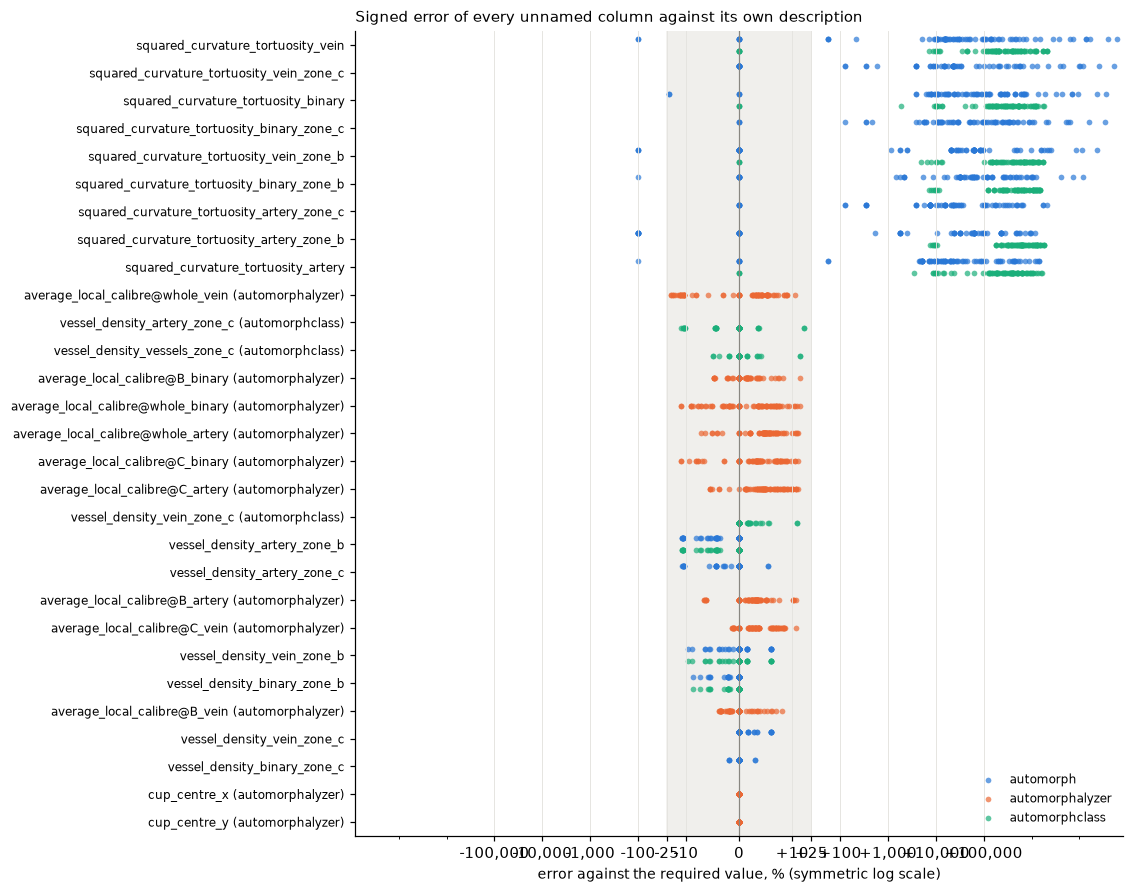

In [16]:
if not CLAIMED.empty:
    order = list(
        CLAIMED.groupby(ROW)["error"].max().sort_values(ascending=False).index
    )
    se.strips(
        CLAIMED,
        order,
        IMPLEMENTATIONS,
        "Signed error of every unnamed column against its own description",
        index=ROW,
    )
    plt.show()

## 6. The cup-to-disc ratios

The synthetic cup is an ellipse on the disc's centre whose horizontal and
vertical diameters are 0.40 and 0.55 of the disc's. A **vertical** cup-to-disc ratio is read along
the image's columns, so turning the photograph moves it, by an amount the geometry gives exactly:
at 90° the vertical and horizontal ratios have swapped. The line is what the geometry requires at
each angle; the dots are what each implementation said. AutoMorph's come from its own driver,
`optic_disc_centre`, and its descendants' from the functions that replaced it.

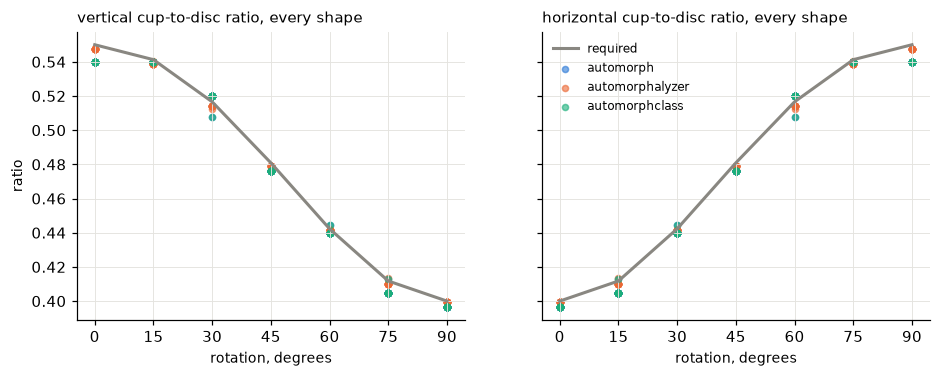

median error worst error
native         implementation                          
CDR_horizontal automorph               0.0%        1.9%
               automorphalyzer         0.0%        0.0%
               automorphclass          0.0%        1.9%
CDR_vertical   automorph               0.0%        1.9%
               automorphalyzer         0.0%        0.0%
               automorphclass          0.0%        1.9%

In [17]:
ratios = AGAINST[AGAINST["canonical"].str.startswith("landmarks/CDR")]
if ratios.empty:
    print("no implementation in this group answered a cup-to-disc ratio")
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
    for ax, which in zip(axes, ("vertical", "horizontal"), strict=True):
        name = f"landmarks/CDR-{which}"
        here = ratios[ratios["canonical"] == name]
        required = here.groupby("rotation")["truth"].first()
        ax.plot(required.index, required.values, color="#898781", linewidth=2, label="required")
        for colour, slug in zip(se.COLOURS, IMPLEMENTATIONS, strict=False):
            mine = here[here["implementation"] == slug]
            if mine.empty:
                continue
            ax.scatter(mine["rotation"], mine["value"], s=16, color=colour, alpha=0.6, label=slug)
        ax.set_title(f"{which} cup-to-disc ratio, every shape", fontsize=10, loc="left")
        ax.set_xlabel("rotation, degrees", fontsize=9)
        ax.set_xticks(sorted(here["rotation"].unique()))
        ax.grid(color="#e4e3df", linewidth=0.6)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    axes[0].set_ylabel("ratio", fontsize=9)
    axes[1].legend(fontsize=8, frameon=False)
    plt.show()
    display(
        se.legible(
            ratios.groupby([ROW, "implementation"])["error"]
            .agg(["median", "max"])
            .rename(columns={"median": "median error", "max": "worst error"})
        )
    )

## 7. The best and the worst biomarkers in this group

For each implementation, its catalogued biomarkers ordered by how close they came to the geometry,
judged by their **worst** case over every shape and angle, then by their median. *Best* lists every
biomarker inside the noise floor everywhere, and at least the closest few besides (never more than
half of what it answers). *Worst* lists, of the biomarkers out by more than 25% somewhere, the five
furthest, with the shape and angle where each was furthest.

This orders biomarkers within one program, not programs: it says which of an implementation's
numbers can be taken at face value on these shapes, and which cannot.

In [18]:
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    best, worst = se.best_and_worst(AGAINST, slug, by=ROW)
    heading(f"### 7.{number} {slug}")
    heading(f"**Best** — {len(best)} biomarker(s)")
    shown = best.copy()
    shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
    display(commented(shown))
    heading(f"**Worst** — out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere")
    if worst.empty:
        print(f"nothing it answers is out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    else:
        shown = worst.copy()
        shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
        display(commented(shown))

### 7.1 automorph

**Best** — 5 biomarker(s)

,worst,median,renderings,worst on,canonical
native,,,,,
Disc_height,1.3%,0.0%,91,arc 30°,landmarks/disc-diameter-vertical
Disc_width,1.3%,0.0%,91,arc 30°,landmarks/disc-diameter-horizontal
vessel_density_binary,1.3%,0.0%,91,spokes-disc-centred 45°,density/over-image/vessels
CDR_horizontal,1.9%,0.0%,91,arc 90°,landmarks/CDR-horizontal
CDR_vertical,1.9%,0.0%,91,arc 0°,landmarks/CDR-vertical


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on,canonical
native,,,,,
tortuosity_density_vein_zone_b,"330,243×","93,868×",77,crossing 30°,automorph: tortuosity/grisan-density/vein/B/mean; automorphalyzer: tortuosity/grisan-d...
tortuosity_density_artery_zone_b,"329,877×","122,842×",77,arc 90°,automorph: tortuosity/grisan-density/artery/B/mean; automorphalyzer: tortuosity/grisan...
tortuosity_density_binary_zone_b,"322,502×","140,873×",77,clothoid 60°,automorph: tortuosity/grisan-density/vessels/B/mean; automorphalyzer: tortuosity/grisa...
tortuosity_density_vein_zone_c,"202,616×","83,315×",77,arc 30°,tortuosity/grisan-density/vein/C/mean
tortuosity_density_artery_zone_c,"201,751×","100,497×",77,straight 60°,tortuosity/grisan-density/artery/C/mean


### 7.2 automorphalyzer

... (5 outputs left out)

**Best** — 5 biomarker(s)

,worst,median,renderings,worst on,canonical
native,,,,,
Disc_height,1.3%,0.0%,91,arc 30°,landmarks/disc-diameter-vertical
Disc_width,1.3%,0.0%,91,arc 30°,landmarks/disc-diameter-horizontal
vessel_density_binary,1.3%,0.0%,91,spokes-disc-centred 45°,density/over-image/vessels
CDR_horizontal,1.9%,0.0%,91,arc 90°,landmarks/CDR-horizontal
CDR_vertical,1.9%,0.0%,91,arc 0°,landmarks/CDR-vertical


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on,canonical
native,,,,,
tortuosity_density_vein_zone_b,"6,338×","2,807×",77,crossing 15°,automorph: tortuosity/grisan-density/vein/B/mean; automorphalyzer: tortuosity/grisan-d...
tortuosity_density_binary_zone_b,"6,196×","2,904×",77,crossing 15°,automorph: tortuosity/grisan-density/vessels/B/mean; automorphalyzer: tortuosity/grisa...
tortuosity_density_artery_zone_b,"6,051×","3,177×",77,crossing 15°,automorph: tortuosity/grisan-density/artery/B/mean; automorphalyzer: tortuosity/grisan...
tortuosity_density_vein,"3,377×","1,481×",84,crossing 15°,automorph: tortuosity/grisan-density/vein/mean; automorphalyzer: tortuosity/grisan-den...
tortuosity_density_binary,"3,320×","1,502×",84,straight 15°,automorph: tortuosity/grisan-density/vessels/mean; automorphalyzer: tortuosity/grisan-...


### 7.4 Across the group

The same question asked of the group as a whole: for each canonical biomarker some member
computes, the member that came closest and its worst error. A biomarker is the group's best when
some member measures it to within the floor; its worst when even the closest member is far.

In [19]:
closest = AGAINST.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
GROUP_TABLE = pd.DataFrame(
    {
        # Siblings that tie are named together: PVBM and OCULAR run the same code, so picking one
        # would credit it with a result that belongs to both.
        "closest member": closest.apply(
            lambda row: " = ".join(row.index[row == row.min()]), axis=1
        ),
        "its worst error": closest.min(axis=1),
        "members answering": closest.notna().sum(axis=1),
    }
).sort_values("its worst error")
heading(
    f"**{int((GROUP_TABLE['its worst error'] == 0).sum())} of {len(GROUP_TABLE)}** named "
    f"columns are measured to within the floor by at least one member. The closest five, then the "
    f"five furthest of those out by more than {GROUND_TRUTH_TOLERANCE:.0%} even at their closest:"
)
furthest = GROUP_TABLE[GROUP_TABLE["its worst error"] > GROUND_TRUTH_TOLERANCE].tail(5).iloc[::-1]
display(
    commented(
        pd.concat({"closest": GROUP_TABLE.drop(index=furthest.index).head(5), "furthest": furthest})
        .rename_axis(["", ROW])
        .assign(**{"its worst error": lambda t: t["its worst error"].map(se.readable)})
    )
)

**4 of 57** named columns are measured to within the floor by at least one member. The closest five, then the five furthest of those out by more than 25% even at their closest:

closest member its worst error  members answering                                                                                  canonical
         native                                                                                                                                                                         
closest  CDR_vertical                      automorphalyzer            0.0%                  3                                                                     landmarks/CDR-vertical
         CDR_horizontal                    automorphalyzer            0.0%                  3                                                                   landmarks/CDR-horizontal
         Disc_width                        automorphalyzer            0.0%                  3                                                         landmarks/disc-diameter-horizontal
         Disc_height                       automorphalyzer            0.0%                  3                                                           landmarks/disc-diameter-vertical
         Cup_width                         automorphalyzer            1.3%                  3                                                          landmarks/cup-diameter-horizontal
furthest tortuosity_density_vein_zone_c          automorph        202,616×                  2                                                      tortuosity/grisan-density/vein/C/mean
         tortuosity_density_artery_zone_c        automorph        201,751×                  2                                                    tortuosity/grisan-density/artery/C/mean
         tortuosity_density_binary_zone_c        automorph        201,021×                  2                                                   tortuosity/grisan-density/vessels/C/mean
         tortuosity_density_vein_zone_b     automorphclass          6,338×                  3  automorph: tortuosity/grisan-density/vein/B/mean; automorphalyzer: tortuosity/grisan-d...
         tortuosity_density_binary_zone_b   automorphclass          6,196×                  3  automorph: tortuosity/grisan-density/vessels/B/mean; automorphalyzer: tortuosity/grisa...

## 8. Summary

Two counts per implementation, each as a fraction so its denominator is visible. Rotation can be
checked on anything that returned a number; agreement only on what has a value to agree with, by
canonical name or by its own description.

In [20]:
EVERY_ROTATION = pd.concat([se.rotation(EVIDENCE, True), se.rotation(EVIDENCE, False)])
summary = {}
for slug in IMPLEMENTATIONS:
    steady = EVERY_ROTATION.loc[slug].dropna() if slug in EVERY_ROTATION.index.get_level_values(0) else pd.Series(dtype=float)
    named = AGAINST[AGAINST["implementation"] == slug].groupby(ROW)["error"].max()
    own = CLAIMED[CLAIMED["implementation"] == slug].groupby("own")["error"].max()
    summary[slug] = {
        "move with the image": f"{int((steady > ROTATION_TOLERANCE).sum())} / {len(steady)}",
        "disagree with the geometry (canonical)": f"{int((named > GROUND_TRUTH_TOLERANCE).sum())} / {len(named)}",
        "disagree with their own description": f"{int((own > GROUND_TRUTH_TOLERANCE).sum())} / {len(own)}",
        "median error, canonical": f"{100 * AGAINST.loc[AGAINST['implementation'] == slug, 'error'].median():.1f}%",
        "exceptions": int((TROUBLES["implementation"] == slug).sum()),
        "seconds per image": round(EVIDENCE.measured[slug]["seconds"].astype(float).mean(), 1),
    }
pd.DataFrame(summary)

,automorph,automorphalyzer,automorphclass
move with the image,52 / 68,24 / 44,48 / 56
disagree with the geometry (canonical),43 / 57,19 / 39,18 / 33
disagree with their own description,9 / 15,0 / 11,6 / 12
"median error, canonical",8.6%,5.6%,6.7%
exceptions,42,21,0
seconds per image,8.5,7.3,0.5


## 9. What this group's evidence shows

*Our reading of the tables above, on the run of 2026-11-22. Every figure is one this notebook
printed; the authors' own claims are in §1.1 and are not restated as ours.*

*Since 2026-11-22 every member returns every column its own run writes* — AutoMorph 72, through its
own M2 hand-off, disc driver and both copies of retipy; AutoMorphClass 60, through its pipeline's
`forward`; AutoMorphalyzer 66. Rows are AutoMorph's own column names, each rewrite's column on the
row of the AutoMorph column it rewrites.

**The cup-to-disc ratios are the one thing this group measures right.** All three read both ratios
from the disc and cup they are handed and land within 1.9% on every shape at every angle,
following the swap the geometry requires as the picture turns (§6) — AutoMorphalyzer exactly,
AutoMorph and AutoMorphClass a pixel short on their 912 × 912 maps.

**AutoMorph's central retinal equivalents are the best of their kind outside VascX.** In zone B its
Knudtson and Hubbard equivalents have medians of 3–12% and worst cases of 42–73%, and move by at
most 10.4% when the picture turns; its Hubbard ratio `AVR_Hubbard_zone_b` is never more than 13.8%
out, where PVBM's is 47%, because AutoMorph applies Hubbard's micron constants to widths it has
already put in microns. Zone C is worse (worst 85–149%). AutoMorphalyzer's zone-B Knudtson
equivalents are close at the median (2.7–3.4%) and as bad at worst (52–67%); its ratios `AVR_B` and
`AVR_C` are **50% out at the median**, which is its `merge_results` quirk: where both equivalents
failed, −1 over −1 is a ratio of 1, and it keeps it.

**Calibre is right on most shapes and far out on diagonal vessels.** Length-weighted width has a
median error of 10–13% in all three, but AutoMorph and AutoMorphClass — which now measure the same
912 × 912 maps and return the same whole-picture widths — are 59–184% out on vessels at 45°, and
width moves by 63–132% as the picture turns. AutoMorphalyzer, measuring at the size it is handed,
is 40–68% out at worst.

**The rewrites fixed AutoMorph's tortuosity and kept its Grisan density.** AutoMorph's mean Hart τ1
(arc over chord) is up to 161 times the geometry's value and moves by 350–640% under rotation: on
its own 912 skeleton, retipy finds vessel pieces with almost no chord, and a mean over vessels lets
one of them dominate. AutoMorphalyzer is 15–23% out at worst and AutoMorphClass, length-weighted,
under 10% over the whole picture — though its zone B is 60% out, and on `disjoint`, where nothing
reaches zone B, it returns 0.0 for an arc over chord, a value no curve can have. Grisan's density is
wrong in all three, by 170,000–335,000 times in AutoMorph and AutoMorphalyzer and 3,300–6,300 times
in AutoMorphClass, on shapes whose geometry requires nought.

**Density is the group's strong family.** Vessel area over the image is within 1.3–11.5% in every
member; box-counting dimension is 18–33% out over the whole picture and 39–53% in zone B, against a
value no finite raster reaches.

**Held to their own description**, AutoMorphalyzer's sixteen unnamed columns all land within 25%.
The squared-curvature column of AutoMorph and AutoMorphClass does not: it is named for Hart's
∫κ² ds and returns tens to tens of thousands of times that value.

**Where a zone is empty, AutoMorph declines and AutoMorphalyzer raises.** On `disjoint` AutoMorph's
zone stage finds no window and its drivers write −1, read here as no answer (42 caught exceptions);
AutoMorphalyzer raises in all three of its measuring passes (21).

**Which to reach for, within this lineage:** AutoMorph itself for the central retinal equivalents
and the Hubbard ratio; AutoMorphClass for whole-picture tortuosity and speed (0.5 s an image); any of
the three for the cup-to-disc ratios; none of them for Grisan density, or for calibre on vessels far
from the image axes.